# Climate Module — Baseline Model Improvement

**Project:** PLEXA — A Multi-Modal Smart City Digital Twin and Cascading Resilience Engine  
**Author:** Muhammad Kaleem  
**Role:** Climate Module Lead  
**Notebook:** 03_climate_model_improvement.ipynb

---

## 1. Objective

Investigate the limitations of the existing climate baseline and evaluate
controlled improvements to next-hour street flooding report prediction.

Each prediction represents whether one physical street segment receives
at least one qualifying NYC 311 street or highway flooding report during
the hour beginning at the prediction timestamp.

## 2. Starting Model

The reference model is the regularized histogram gradient boosting model
with ten input features:

- **Street characteristics:** mean elevation, absolute endpoint grade,
  terrain relief, and segment length.
- **Rainfall:** accumulated rainfall over 1, 3, 6, and 24 hours, using the
  existing three-hour availability assumption.
- **Historical context:** qualifying positive segment-hours within the
  previous 365 days for the street segment and its radar cell, using the
  existing history cutoff policy.

The model package supplied to the cascading engine remains unchanged
while improvement experiments are developed separately.

## 3. Investigation Plan

1. Verify the saved model, experiment settings, and reference results.
2. Review missed reports, alert patterns, and data coverage.
3. Investigate rainfall timing, historical context, and feature limitations.
4. Define and record each proposed experiment before fitting.
5. Compare candidates using consistent development data and metrics.

## 4. Evaluation Approach

- Retain the existing chronological split definitions for traceability.
- Treat 2025 as reused development data.
- Treat the previously examined 2026 test results as historical evaluation
  evidence, not an untouched test for subsequent experiments.
- Reserve a separate, unused evaluation period before making claims
  about improved generalization.
- Report precision, recall, F1, approximate average precision, and alert volume.


## 1. Existing Model Performance

Review the released model’s confusion matrix and saved development metrics
before beginning improvement experiments.

These results use 2025 development data, which was reused during tuning.
Class 0 means no qualifying report observed; class 1 means a report observed.

Model: climate-history-v3-02-experimental-01
Evaluation: reused 2025 development data
Frozen alert threshold: 0.001456699474


,Metric,Value
0,Evaluated street-hours,"782,119,322"
1,Observed positive street-hours,"3,383"
2,Precision,0.2526%
3,Recall,0.5321%
4,F1,0.003425
5,Approximate average precision,0.00010502
6,Alert street-hours,"7,127"
7,Mean alerts per 24 hours,19.91


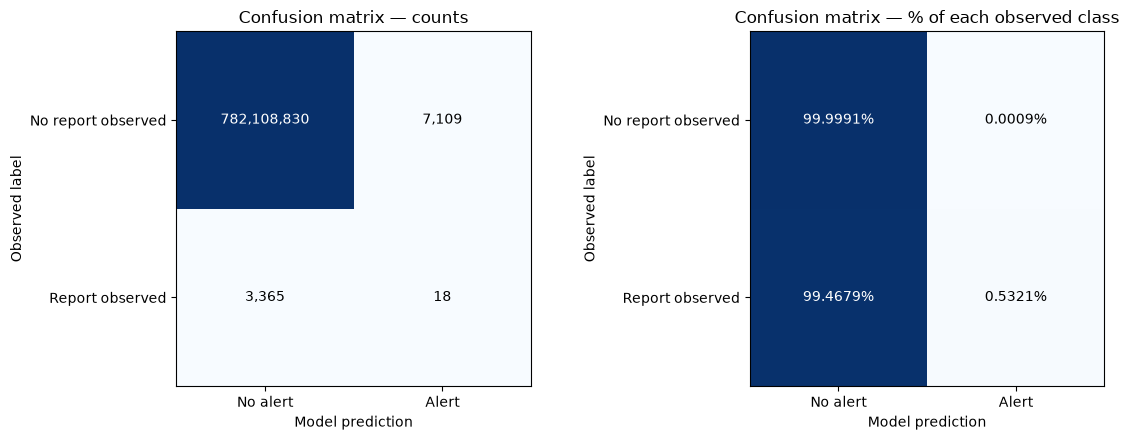

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project from either its root or notebooks directory.
PROJECT_ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "config/climate_history_release_v3_02.json").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project configuration.")

release_path = (
    PROJECT_ROOT / "config/climate_history_release_v3_02.json"
)
release = json.loads(release_path.read_text())
metrics = release["development_metrics"]

# Rows = observed labels; columns = model predictions.
matrix = np.array([
    [metrics["TN"], metrics["FP"]],
    [metrics["FN"], metrics["TP"]],
], dtype=np.int64)

assert matrix.sum() == metrics["rows"]
assert matrix[1].sum() == metrics["positive_rows"]

row_percent = (
    matrix / matrix.sum(axis=1, keepdims=True) * 100
)

print("Model:", release["release_id"])
print("Evaluation: reused 2025 development data")
print(f"Frozen alert threshold: {metrics['threshold']:.12f}")

summary = pd.DataFrame({
    "Metric": [
        "Evaluated street-hours",
        "Observed positive street-hours",
        "Precision",
        "Recall",
        "F1",
        "Approximate average precision",
        "Alert street-hours",
        "Mean alerts per 24 hours",
    ],
    "Value": [
        f"{metrics['rows']:,}",
        f"{metrics['positive_rows']:,}",
        f"{metrics['precision']:.4%}",
        f"{metrics['recall']:.4%}",
        f"{metrics['F1']:.6f}",
        f"{metrics['approximate_AP']:.8f}",
        f"{metrics['alerts']:,}",
        f"{metrics['mean_alerts_per_24h']:.2f}",
    ],
})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, values, title, percentage in [
    (axes[0], matrix, "Confusion matrix — counts", False),
    (axes[1], row_percent, "Confusion matrix — % of each observed class", True),
]:
    ax.imshow(values, cmap="Blues")

    for row in range(2):
        for col in range(2):
            label = (
                f"{values[row, col]:.4f}%"
                if percentage else f"{values[row, col]:,}"
            )
            ax.text(
                col, row, label,
                ha="center", va="center",
                color=(
                    "white"
                    if values[row, col] > values.max() / 2
                    else "black"
                ),
            )

    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["No alert", "Alert"],
        yticklabels=["No report observed", "Report observed"],
        xlabel="Model prediction",
        ylabel="Observed label",
        title=title,
    )

plt.tight_layout()
plt.show()

## 2. Rainfall Coverage in the Training Sample

Compare rainfall bands for positive and negative training examples.
Sampling weights estimate the population represented by the sample.

This review does not change the model or training data.

In [2]:
import duckdb

database_path = (
    PROJECT_ROOT / "data/processed/baseline_dataset_v1/dataset.duckdb"
)

if not database_path.is_file():
    raise FileNotFoundError(database_path)

with duckdb.connect(str(database_path), read_only=True) as connection:
    connection.execute("SET threads=2")
    connection.execute("SET memory_limit='2GB'")

    rainfall_review = connection.execute("""
        WITH banded AS (
            SELECT
                label,
                sample_weight,
                CASE
                    WHEN rain_24h_mm = 0 THEN 0
                    WHEN rain_24h_mm <= 1 THEN 1
                    WHEN rain_24h_mm <= 10 THEN 2
                    WHEN rain_24h_mm <= 25 THEN 3
                    WHEN rain_24h_mm <= 50 THEN 4
                    ELSE 5
                END AS band_order
            FROM training_sample
        )
        SELECT
            band_order,
            count(*) FILTER (WHERE label = 0) AS sampled_negatives,
            count(*) FILTER (WHERE label = 1) AS sampled_positives,
            sum(CASE WHEN label = 0 THEN sample_weight ELSE 0 END)
                AS estimated_negative_population,
            sum(CASE WHEN label = 1 THEN sample_weight ELSE 0 END)
                AS positive_population
        FROM banded
        GROUP BY band_order
        ORDER BY band_order
    """).df()

band_names = [
    "0 mm", "(0, 1] mm", "(1, 10] mm",
    "(10, 25] mm", "(25, 50] mm", ">50 mm",
]

rainfall_review.insert(
    0,
    "rain_24h_band",
    rainfall_review["band_order"].map(dict(enumerate(band_names))),
)

population = (
    rainfall_review["estimated_negative_population"]
    + rainfall_review["positive_population"]
)

rainfall_review["positives_per_million_estimate"] = (
    rainfall_review["positive_population"] / population * 1_000_000
)

assert rainfall_review["sampled_negatives"].sum() == 654_040
assert rainfall_review["sampled_positives"].sum() == 12_817

display(
    rainfall_review.drop(columns="band_order").style.format({
        "sampled_negatives": "{:,.0f}",
        "sampled_positives": "{:,.0f}",
        "estimated_negative_population": "{:,.0f}",
        "positive_population": "{:,.0f}",
        "positives_per_million_estimate": "{:.2f}",
    })
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rain_24h_band,sampled_negatives,sampled_positives,estimated_negative_population,positive_population,positives_per_million_estimate
0,0 mm,"423,150","4,201","2,115,750,000","4,201",1.99
1,"(0, 1] mm","46,128",624,"230,640,000",624,2.71
2,"(1, 10] mm","115,131","2,810","575,655,000","2,810",4.88
3,"(10, 25] mm","49,004","2,242","245,020,000","2,242",9.15
4,"(25, 50] mm","16,736","1,762","83,680,000","1,762",21.06
5,>50 mm,"3,891","1,178","19,455,000","1,178",60.55


In [3]:
print("Training sample totals match the original experiment.")
print("Rainfall windows retain the existing three-hour availability lag.")
print("Weighted population counts are sampling estimates.")
print("No model changed; no validation or test data queried.")

Training sample totals match the original experiment.
Rainfall windows retain the existing three-hour availability lag.
Weighted population counts are sampling estimates.
No model changed; no validation or test data queried.


## 3. Heavy-Rain Training Coverage

Review the dates and radar cells represented by training rows with
more than 50 mm of lagged 24-hour rainfall.

Calendar dates are used to inspect coverage; they are not independent storms.

In [4]:
with duckdb.connect(str(database_path), read_only=True) as connection:
    connection.execute("SET threads=2")
    connection.execute("SET memory_limit='2GB'")
    connection.execute("SET TimeZone='UTC'")

    heavy_rain_daily = connection.execute("""
        SELECT
            CAST(prediction_time_utc AS DATE) AS date_utc,
            count(*) FILTER (WHERE label = 0) AS sampled_negatives,
            count(*) FILTER (WHERE label = 1) AS positive_rows,
            count(DISTINCT (grid_id, cell_id))
                FILTER (WHERE label = 0) AS negative_radar_cells,
            count(DISTINCT (grid_id, cell_id))
                FILTER (WHERE label = 1) AS positive_radar_cells
        FROM training_sample
        WHERE rain_24h_mm > 50
        GROUP BY 1
        ORDER BY 1
    """).df()

assert heavy_rain_daily["sampled_negatives"].sum() == 3_891
assert heavy_rain_daily["positive_rows"].sum() == 1_178

heavy_rain_daily["month"] = (
    pd.to_datetime(heavy_rain_daily["date_utc"])
    .dt.to_period("M")
    .astype(str)
)

monthly_coverage = heavy_rain_daily.groupby("month").agg(
    represented_dates=("date_utc", "size"),
    sampled_negatives=("sampled_negatives", "sum"),
    positive_rows=("positive_rows", "sum"),
)

print("Heavy-rain training coverage by month:")
display(monthly_coverage)

print("Ten dates with the most sampled heavy-rain negatives:")
display(
    heavy_rain_daily.nlargest(10, "sampled_negatives")
    .drop(columns="month")
    .reset_index(drop=True)
)

top_ten_share = (
    heavy_rain_daily.nlargest(10, "sampled_negatives")
    ["sampled_negatives"].sum()
    / heavy_rain_daily["sampled_negatives"].sum()
)

print(f"Represented UTC dates: {len(heavy_rain_daily):,}")
print(f"Negative examples on the ten largest dates: {top_ten_share:.1%}")
print("Radar-cell counts are distinct within each date.")
print("No model changed; only training data was queried.")

BinderException: Binder Error: Referenced column "grid_id" not found in FROM clause!
Candidate bindings: "terrain_relief_m", "rain_1h_mm", "rain_3h_mm", "rain_6h_mm", "terrain_endpoint_grade_abs"

LINE 6:             count(DISTINCT (grid_id, cell_id))
                                    ^

In [5]:
with duckdb.connect(str(database_path), read_only=True) as connection:
    connection.execute("SET threads=2")
    connection.execute("SET memory_limit='2GB'")
    connection.execute("SET TimeZone='UTC'")

    # Prevent duplicate street mappings from multiplying training rows.
    duplicate_streets = connection.execute("""
        SELECT count(*)
        FROM (
            SELECT street_segment_id
            FROM street_features
            GROUP BY street_segment_id
            HAVING count(*) > 1
        )
    """).fetchone()[0]

    if duplicate_streets:
        raise ValueError("Duplicate street IDs in street_features.")

    heavy_rain_daily = connection.execute("""
        SELECT
            CAST(t.prediction_time_utc AS DATE) AS date_utc,
            count(*) FILTER (WHERE t.label = 0) AS sampled_negatives,
            count(*) FILTER (WHERE t.label = 1) AS positive_rows,
            count(DISTINCT (s.grid_id, s.cell_id))
                FILTER (WHERE t.label = 0) AS negative_radar_cells,
            count(DISTINCT (s.grid_id, s.cell_id))
                FILTER (WHERE t.label = 1) AS positive_radar_cells
        FROM training_sample AS t
        JOIN street_features AS s
            ON t.street_segment_id = s.street_segment_id
        WHERE t.rain_24h_mm > 50
        GROUP BY 1
        ORDER BY 1
    """).df()

assert heavy_rain_daily["sampled_negatives"].sum() == 3_891
assert heavy_rain_daily["positive_rows"].sum() == 1_178

heavy_rain_daily["month"] = (
    pd.to_datetime(heavy_rain_daily["date_utc"])
    .dt.to_period("M")
    .astype(str)
)

monthly_coverage = heavy_rain_daily.groupby("month").agg(
    represented_dates=("date_utc", "size"),
    sampled_negatives=("sampled_negatives", "sum"),
    positive_rows=("positive_rows", "sum"),
)

print("Heavy-rain training coverage by month:")
display(monthly_coverage)

top_dates = heavy_rain_daily.nlargest(10, "sampled_negatives")

print("Ten dates with the most sampled heavy-rain negatives:")
display(
    top_dates.drop(columns="month").reset_index(drop=True)
)

top_ten_share = (
    top_dates["sampled_negatives"].sum()
    / heavy_rain_daily["sampled_negatives"].sum()
)

print(f"Represented UTC dates: {len(heavy_rain_daily):,}")
print(f"Negative examples on the ten largest dates: {top_ten_share:.1%}")
print("Radar-cell counts are distinct within each date.")
print("Calendar dates do not represent independent storms.")
print("No model changed; only training data was queried.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Heavy-rain training coverage by month:


,represented_dates,sampled_negatives,positive_rows
month,,,
2021-02,2,37,0
2021-05,1,1,0
2021-07,5,212,47
2021-08,4,431,145
2021-09,4,226,301
2021-10,2,327,58
2022-01,2,3,0
2022-04,2,4,1
2022-05,2,2,0


Ten dates with the most sampled heavy-rain negatives:


,date_utc,sampled_negatives,positive_rows,negative_radar_cells,positive_radar_cells
0,2024-03-24,330,9,273,8
1,2024-01-10,307,38,247,31
2,2021-08-23,284,51,224,47
3,2023-05-01,282,75,234,65
4,2023-09-30,229,32,186,25
5,2021-10-27,206,18,186,16
6,2023-12-19,180,5,157,5
7,2021-09-02,144,278,131,173
8,2023-04-30,144,4,128,4
9,2023-12-18,138,52,121,48


Represented UTC dates: 70
Negative examples on the ten largest dates: 57.7%
Radar-cell counts are distinct within each date.
Calendar dates do not represent independent storms.
No model changed; only training data was queried.


## 4. Heavy-Rain Negative Sampling Review

Compare sampled negative rows with the complete eligible heavy-rain
training population by UTC date.

This distinguishes concentration in the source data from concentration
introduced by sampling.

In [6]:
import time

started = time.perf_counter()

with duckdb.connect(str(database_path), read_only=True) as connection:
    connection.execute("SET threads=2")
    connection.execute("SET memory_limit='2GB'")
    connection.execute("SET TimeZone='UTC'")

    full_heavy_rain_daily = connection.execute("""
        SELECT
            CAST(prediction_time_utc AS DATE) AS date_utc,
            count(*) AS eligible_negatives
        FROM eligible
        WHERE split = 'train'
          AND label = 0
          AND rain_24h_mm > 50
        GROUP BY 1
        ORDER BY 1
    """).df()

sample_daily = heavy_rain_daily[
    ["date_utc", "sampled_negatives"]
].copy()

for frame in [full_heavy_rain_daily, sample_daily]:
    frame["date_utc"] = pd.to_datetime(frame["date_utc"])

sampling_review = full_heavy_rain_daily.merge(
    sample_daily,
    on="date_utc",
    how="left",
    validate="one_to_one",
)

sampling_review["sampled_negatives"] = (
    sampling_review["sampled_negatives"]
    .fillna(0)
    .astype("int64")
)

keep_fraction = 0.0002

sampling_review["expected_sample_count"] = (
    sampling_review["eligible_negatives"] * keep_fraction
)
sampling_review["actual_keep_percent"] = (
    sampling_review["sampled_negatives"]
    / sampling_review["eligible_negatives"] * 100
)

assert sampling_review["sampled_negatives"].sum() == 3_891

total_full = int(sampling_review["eligible_negatives"].sum())
total_sample = int(sampling_review["sampled_negatives"].sum())

largest_dates = sampling_review.nlargest(10, "eligible_negatives")

full_top_share = (
    largest_dates["eligible_negatives"].sum() / total_full
)
sample_same_dates_share = (
    largest_dates["sampled_negatives"].sum() / total_sample
)

print(f"Full eligible heavy-rain negatives: {total_full:,}")
print(f"Sampled heavy-rain negatives: {total_sample:,}")
print(f"Expected sample count at 0.02%: {total_full * keep_fraction:,.1f}")
print(f"Actual overall keep rate: {total_sample / total_full:.4%}")

print("\nTen dates with the largest eligible negative populations:")
display(
    largest_dates.reset_index(drop=True).style.format({
        "eligible_negatives": "{:,.0f}",
        "sampled_negatives": "{:,.0f}",
        "expected_sample_count": "{:,.2f}",
        "actual_keep_percent": "{:.4f}%",
    })
)

print(f"Full-population share on these dates: {full_top_share:.1%}")
print(f"Sample share on the same dates: {sample_same_dates_share:.1%}")

unsampled_dates = sampling_review[
    sampling_review["sampled_negatives"] == 0
]

print(f"\nDates with eligible negatives but no sampled negatives: "
      f"{len(unsampled_dates):,}")

if not unsampled_dates.empty:
    display(
        unsampled_dates.nlargest(10, "eligible_negatives")
        .reset_index(drop=True)
    )

print(f"\nElapsed: {time.perf_counter() - started:.1f} seconds")
print("Expected counts are sampling expectations, not required exact totals.")
print("No model changed; only training data was queried.")

Full eligible heavy-rain negatives: 19,676,177
Sampled heavy-rain negatives: 3,891
Expected sample count at 0.02%: 3,935.2
Actual overall keep rate: 0.0198%

Ten dates with the largest eligible negative populations:


,date_utc,eligible_negatives,sampled_negatives,expected_sample_count,actual_keep_percent
0,2024-03-24 00:00:00,"1,649,501",330,329.90,0.0200%
1,2021-08-23 00:00:00,"1,548,593",284,309.72,0.0183%
2,2023-05-01 00:00:00,"1,471,463",282,294.29,0.0192%
3,2024-01-10 00:00:00,"1,440,507",307,288.10,0.0213%
4,2021-10-27 00:00:00,"1,103,075",206,220.62,0.0187%
5,2023-09-30 00:00:00,"1,091,100",229,218.22,0.0210%
6,2023-12-19 00:00:00,"863,057",180,172.61,0.0209%
7,2023-04-30 00:00:00,"777,030",144,155.41,0.0185%
8,2021-09-02 00:00:00,"755,017",144,151.00,0.0191%
9,2023-12-18 00:00:00,"750,911",138,150.18,0.0184%


Full-population share on these dates: 58.2%
Sample share on the same dates: 57.7%

Dates with eligible negatives but no sampled negatives: 13


,date_utc,eligible_negatives,sampled_negatives,expected_sample_count,actual_keep_percent
0,2024-11-22,12775,0,2.5550,0.0
1,2022-10-05,11555,0,2.3110,0.0
2,2022-12-16,7045,0,1.4090,0.0
3,2021-05-29,6694,0,1.3388,0.0
4,2023-01-26,5241,0,1.0482,0.0
5,2023-07-19,2788,0,0.5576,0.0
6,2022-12-23,724,0,0.1448,0.0
7,2024-07-01,456,0,0.0912,0.0
8,2024-08-05,169,0,0.0338,0.0
9,2023-07-25,133,0,0.0266,0.0



Elapsed: 1.7 seconds
Expected counts are sampling expectations, not required exact totals.
No model changed; only training data was queried.


## 5. Rainfall-Stratified Sampling Experiment

Increase negative sampling for rows with more than 10 mm of lagged
24-hour rainfall. Keep the existing features, history policy, model
parameters, and chronological boundaries unchanged.

Use inverse inclusion weights and evaluate on the complete 2025
development population. Preserve the model supplied to Anas.

In [7]:
import copy
import hashlib
import json

parent_path = (
    PROJECT_ROOT / "config/climate_history_experiment_v3_02.json"
)
plan_path = (
    PROJECT_ROOT / "config/climate_sampling_experiment_v3_03.json"
)

parent_bytes = parent_path.read_bytes()
parent_plan = json.loads(parent_bytes)
sampling_plan = copy.deepcopy(parent_plan)

# Remove metadata belonging to the previous experiment.
for key in ["parent_run_id", "parent_selection", "change"]:
    sampling_plan.pop(key, None)

sampling_plan.update({
    "experiment_id": "climate-sampling-v3-03",
    "status": "planned_not_fitted",
    "parent_experiment": parent_plan["experiment_id"],
    "parent_config_sha256": hashlib.sha256(parent_bytes).hexdigest(),
    "reference_release": release["release_id"],
    "change": {
        "scope": "negative_sampling_and_inverse_inclusion_weights",
        "rainfall_feature": "rain_24h_mm",
        "reason": "Increase representation of rainy-condition negatives.",
        "improvement_assumed": False,
    },
})

sampling_plan["sampling_policy"] = {
    "source_view": "eligible",
    "source_split": "train",
    "positive_keep_fraction": 1.0,
    "positive_inclusion_weight": 1.0,
    "negative_strata": [
        {
            "condition": "rain_24h_mm <= 10",
            "keep_fraction": 0.0002,
            "hash_modulus": 5000,
            "inverse_inclusion_weight": 5000.0,
        },
        {
            "condition": "rain_24h_mm > 10",
            "keep_fraction": 0.002,
            "hash_modulus": 500,
            "inverse_inclusion_weight": 500.0,
        },
    ],
    "sampling_seed": "plexa-baseline-v1",
    "hash_expression": (
        "md5_number_lower(street_segment_id || '|' || "
        "epoch(prediction_time_utc)::VARCHAR || 'plexa-baseline-v1')"
    ),
    "keep_rule": "hash_expression % stratum_hash_modulus = 0",
    "additional_balanced_class_weights": False,
    "normalize_fitting_weights": False,
    "actual_sample_counts": None,
}

sampling_plan["evaluation_policy"].update({
    "primary_comparison": "approximate_AP_on_full_2025_development",
    "threshold_selection": "maximum_development_F1",
    "threshold_tie_break": "fewest_alerts_then_highest_threshold",
    "report": [
        "precision", "recall", "F1", "TP", "FP", "FN", "TN",
        "alerts", "mean_alerts_per_24h",
    ],
})

# Confirm that model and feature definitions remain unchanged.
for key in [
    "features",
    "history_policy",
    "training_interval",
    "development_interval",
    "proposed_tree_parameters",
]:
    assert sampling_plan[key] == parent_plan[key]

# Exclusive creation prevents accidentally overwriting a frozen plan.
with plan_path.open("x") as file:
    json.dump(sampling_plan, file, indent=2)
    file.write("\n")

print("Experiment plan saved:", plan_path)
print("Features and model parameters unchanged.")
print("No new sample created and no model fitted.")

Experiment plan saved: /Users/macbookairm3/Documents/Plexa-A-Multi-Modal-Smart-City-Digital-Twin-and-Cascading-Resilience-Engine/config/climate_sampling_experiment_v3_03.json
Features and model parameters unchanged.
No new sample created and no model fitted.
